# Нобелевские лауреаты

Посмотрим на страны рождения, возраст первой премии и долю женщин.
а в конце разберем слова из мотиваций.
Данные из [Nobel Prize API](https://api.nobelprize.org/2.1/laureates?limit=1200), копия лежит в `data/laureates.json`

импортиру библиотеки и функции, для вывода таблиц использую Markdown.

In [1]:
import json
import re
from collections import Counter
from itertools import combinations
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import requests
from IPython.display import Markdown, display

from aggregations import (
    count_records, max_value, mean_value, median_value, min_value, top_n,
)
from atribute_manager import add_attribute
from dataset_helpers import (
    aggregate_data, count_missing, filter_data, group_by_attributes,
)
from json_dict_processing import process_dictionary_with_config
from laureates_configs import process_orgs, process_persons
from stopwords import STOPWORDS


def show_table(rows, columns):
    lines = ['| ' + ' | '.join(title for _, title in columns) + ' |',
             '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    for row in rows:
        values = [row.get(field) for field, _ in columns]
        values = [round(value, 2) if isinstance(value, float) else value
                  for value in values]
        fields = [str(value).replace('|', '/') for value in values]
        lines.append('| ' + ' | '.join(fields) + ' |')
    display(Markdown('\n'.join(lines)))


## 1. Подготовка данных

читаем JSON, если файла нет, скачиваем из API

In [2]:
URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates?limit=1200'
data_path = Path('data/laureates.json')

if data_path.exists():
    laureates = json.loads(data_path.read_text(encoding='utf-8'))
else:
    response = requests.get(
        URL_LAUREATES, headers={'User-Agent': 'Mozilla/5.0'}, timeout=30
    )
    response.raise_for_status()
    laureates = response.json()
    assert len(laureates['laureates']) == laureates['meta']['count']
    data_path.parent.mkdir(exist_ok=True)
    data_path.write_text(json.dumps(laureates), encoding='utf-8')

assert len(laureates['laureates']) == laureates['meta']['count']
print('Записей:', len(laureates['laureates']))


Записей: 1028


Для людей и организаций беру разные конфиги. Нет поля: `None`, нет премий: пустой список.

In [3]:
def get_laureate_data(laureate):
    if 'knownName' in laureate:
        result = process_persons(laureate)
        result['type_'] = 'person'
    elif 'orgName' in laureate:
        result = process_orgs(laureate)
        result['type_'] = 'org'
    else:
        raise ValueError('Неизвестный тип лауреата')
    return result


example = {'birth': {'year': '1943'}}
config = {'year': (['birth', 'year'], int)}
assert process_dictionary_with_config(example, config) == {'year': 1943}
assert get_laureate_data({'knownName': {'en': 'Test'}})['type_'] == 'person'
assert get_laureate_data({'orgName': {'en': 'Test'}})['type_'] == 'org'

laureates_data = [
    get_laureate_data(laureate) for laureate in laureates['laureates']
]
pprint(laureates_data[0], sort_dicts=False)


{'id': '745',
 'name': 'A. Michael Spence',
 'gender': 'male',
 'birth_year': 1943,
 'country_birth': 'USA',
 'country_now': 'USA',
 'prizes_relevant': [{'prize_amount': 10000000,
                      'prize_amount_adjusted': 15547541,
                      'award_year': 2001,
                      'category_en': 'Economic Sciences',
                      'prize_status': 'received',
                      'motivation': 'for their analyses of markets with '
                                    'asymmetric information'}],
 'type_': 'person'}


## 2. Проверка данных

считаю людей, организации и награждения

In [4]:
persons = filter_data(laureates_data, lambda row: row['type_'] == 'person')
organizations = filter_data(laureates_data, lambda row: row['type_'] == 'org')
prizes = [
    prize for laureate in laureates_data
    for prize in laureate['prizes_relevant']
]
print('Всего записей:', count_records(laureates_data))
print('Людей:', count_records(persons))
print('Организаций:', count_records(organizations))
print('Записей о награждениях:', count_records(prizes))
print('Годы:', min_value(prizes, 'award_year'),
      '-', max_value(prizes, 'award_year'))
print('Статусы:', dict(Counter(prize['prize_status'] for prize in prizes)))


Всего записей: 1028
Людей: 1000
Организаций: 28
Записей о награждениях: 1036
Годы: 1901 - 2026
Статусы: {'received': 1033, 'restricted': 1, 'declined': 2}


считаю число и долю пропусков по полям. Ноль не считаю пропуском. Для людей, организаций и премий проверяю отдельно

In [5]:
missing = count_missing(laureates_data)
missing_share = {
    field: round(count / len(laureates_data), 4)
    for field, count in missing.items()
}
print('Число пропусков:')
pprint(missing)
print('Доля пропусков от всех записей:')
pprint(missing_share)
print('Все поля заполнены:', not any(missing.values()))

print('\nПропуски у людей:')
pprint(count_missing(persons))
print('Пропуски у организаций:')
pprint(count_missing(organizations))
print('Пропуски в записях о призах:')
pprint(count_missing(prizes))


Число пропусков:
{'birth_year': 28,
 'country_birth': 31,
 'country_founded': 1004,
 'country_now': 7,
 'founded_year': 1001,
 'gender': 28,
 'id': 0,
 'name': 0,
 'prizes_relevant': 0,
 'type_': 0}
Доля пропусков от всех записей:
{'birth_year': 0.0272,
 'country_birth': 0.0302,
 'country_founded': 0.9767,
 'country_now': 0.0068,
 'founded_year': 0.9737,
 'gender': 0.0272,
 'id': 0.0,
 'name': 0.0,
 'prizes_relevant': 0.0,
 'type_': 0.0}
Все поля заполнены: False

Пропуски у людей:
{'birth_year': 0,
 'country_birth': 3,
 'country_now': 3,
 'gender': 0,
 'id': 0,
 'name': 0,
 'prizes_relevant': 0,
 'type_': 0}
Пропуски у организаций:
{'country_founded': 4,
 'country_now': 4,
 'founded_year': 1,
 'id': 0,
 'name': 0,
 'prizes_relevant': 0,
 'type_': 0}
Пропуски в записях о призах:
{'award_year': 0,
 'category_en': 0,
 'motivation': 0,
 'prize_amount': 0,
 'prize_amount_adjusted': 0,
 'prize_status': 0}


### Проверка ID

ищу крайние ID, повторы и разрывы нумерации

In [6]:
ids = [int(laureate['id']) for laureate in laureates_data]
id_counts = Counter(ids)
duplicates = {
    laureate_id: count for laureate_id, count in id_counts.items()
    if count > 1
}
sorted_ids = sorted(set(ids))
id_gaps = [
    (left, right) for left, right in zip(sorted_ids, sorted_ids[1:])
    if right - left > 1
]
edge_ids = {min(ids), max(ids)}
edge_records = []
for laureate in laureates_data:
    if int(laureate['id']) in edge_ids:
        edge_records.append({
            'id': laureate['id'],
            'name': laureate['name'],
            'years': sorted(
                prize['award_year'] for prize in laureate['prizes_relevant']
                if prize['award_year'] is not None
            ),
        })

show_table(edge_records, [('id', 'ID'), ('name', 'Имя'), ('years', 'Годы')])
print('Повторяющиеся ID:', duplicates)
print('Пар с разрывом:', len(id_gaps))
print('Пары ID с разрывом:', id_gaps)


| ID | Имя | Годы |
| --- | --- | --- |
| 1070 | Michael Woodford | [2026] |
| 1 | Wilhelm Conrad Röntgen | [1901] |

Повторяющиеся ID: {}
Пар с разрывом: 24
Пары ID с разрывом: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789), (858, 861), (896, 903), (949, 958), (1009, 1011)]


ID сравниваю как числа. Есть разрывы, но число записей совпадает с `meta.count`.

### Поля для анализа

добавляю первую премию, возраст, десятилетие и категории

In [7]:
def get_first_prize(laureate):
    prizes = filter_data(
        laureate['prizes_relevant'],
        lambda prize: prize['award_year'] is not None,
    )
    return min(prizes, key=lambda prize: prize['award_year'], default=None)


laureates_data = add_attribute(laureates_data, 'first_prize', get_first_prize)
for row in laureates_data:
    # если премии нет, поля останутся пустыми
    first_prize = row['first_prize'] or {}
    year = first_prize.get('award_year')
    birth_year = row.get('birth_year')
    row['first_year'] = year
    row['first_category'] = first_prize.get('category_en')
    row['first_decade'] = year // 10 * 10 if year is not None else None
    row['age_first'] = None
    if year is not None and birth_year is not None:
        row['age_first'] = year - birth_year
    row['categories'] = sorted({
        prize['category_en'] for prize in row['prizes_relevant']
        if prize['category_en'] is not None
    })

persons = filter_data(laureates_data, lambda row: row['type_'] == 'person')
organizations = filter_data(laureates_data, lambda row: row['type_'] == 'org')
categories = sorted({
    category for row in persons for category in row['categories']
})


## 3. Страны

беру `country_now` (*это современные границы страны рождения*), людей и организации считаю отдельно

In [8]:
def country_top(records, n=5):
    counts = Counter(row['country_now'] for row in records
                     if row['country_now'])
    rows = [{'country': country, 'count': count}
            for country, count in sorted(counts.items())]
    return top_n(rows, 'count', n)


countries_total = country_top(persons)
print('Люди: топ стран рождения')
show_table(countries_total, [('country', 'Страна'), ('count', 'Лауреатов')])
print('Организации: топ стран основания')
show_table(country_top(organizations), [
    ('country', 'Страна'), ('count', 'Организаций'),
])
print('Людей без страны:', count_missing(persons, ['country_now']))
print('Организаций без страны:', count_missing(organizations, ['country_now']))


Люди: топ стран рождения


| Страна | Лауреатов |
| --- | --- |
| USA | 299 |
| United Kingdom | 94 |
| Germany | 86 |
| France | 64 |
| Japan | 31 |

Организации: топ стран основания


| Страна | Организаций |
| --- | --- |
| USA | 7 |
| Switzerland | 5 |
| France | 2 |
| United Kingdom | 2 |
| Australia | 1 |

Людей без страны: {'country_now': 3}
Организаций без страны: {'country_now': 4}


cравниваю топ-5 стран в каждой категории. Один человек учитывается один раз в рейтинге

In [9]:
countries_by_category = []
for category in categories:
    selected = filter_data(persons, lambda row: category in row['categories'])
    for rank, country in enumerate(country_top(selected), start=1):
        countries_by_category.append({
            'category': category, 'rank': rank, **country,
        })
show_table(countries_by_category, [
    ('category', 'Категория'), ('rank', 'Место'),
    ('country', 'Страна рождения'), ('count', 'Лауреатов'),
])


| Категория | Место | Страна рождения | Лауреатов |
| --- | --- | --- | --- |
| Chemistry | 1 | USA | 59 |
| Chemistry | 2 | Germany | 26 |
| Chemistry | 3 | United Kingdom | 26 |
| Chemistry | 4 | France | 12 |
| Chemistry | 5 | Japan | 9 |
| Economic Sciences | 1 | USA | 56 |
| Economic Sciences | 2 | United Kingdom | 7 |
| Economic Sciences | 3 | Canada | 5 |
| Economic Sciences | 4 | France | 5 |
| Economic Sciences | 5 | the Netherlands | 4 |
| Literature | 1 | France | 12 |
| Literature | 2 | USA | 10 |
| Literature | 3 | Germany | 7 |
| Literature | 4 | Poland | 7 |
| Literature | 5 | Sweden | 7 |
| Peace | 1 | USA | 19 |
| Peace | 2 | France | 10 |
| Peace | 3 | Germany | 5 |
| Peace | 4 | Sweden | 5 |
| Peace | 5 | United Kingdom | 5 |
| Physics | 1 | USA | 71 |
| Physics | 2 | Germany | 27 |
| Physics | 3 | United Kingdom | 25 |
| Physics | 4 | France | 13 |
| Physics | 5 | Japan | 12 |
| Physiology or Medicine | 1 | USA | 85 |
| Physiology or Medicine | 2 | United Kingdom | 25 |
| Physiology or Medicine | 3 | Germany | 20 |
| Physiology or Medicine | 4 | France | 12 |
| Physiology or Medicine | 5 | Sweden | 8 |

смчитаю страны по десятилетиям первой премии и строю график для топ 5 стран

| Десятилетие | Страна-лидер | Лауреатов впервые |
| --- | --- | --- |
| 1900 | France | 9 |
| 1910 | France | 6 |
| 1920 | Germany | 10 |
| 1930 | USA | 14 |
| 1940 | USA | 13 |
| 1950 | USA | 21 |
| 1960 | USA | 20 |
| 1970 | USA | 32 |
| 1980 | USA | 31 |
| 1990 | USA | 42 |
| 2000 | USA | 52 |
| 2010 | USA | 39 |
| 2020 | USA | 27 |

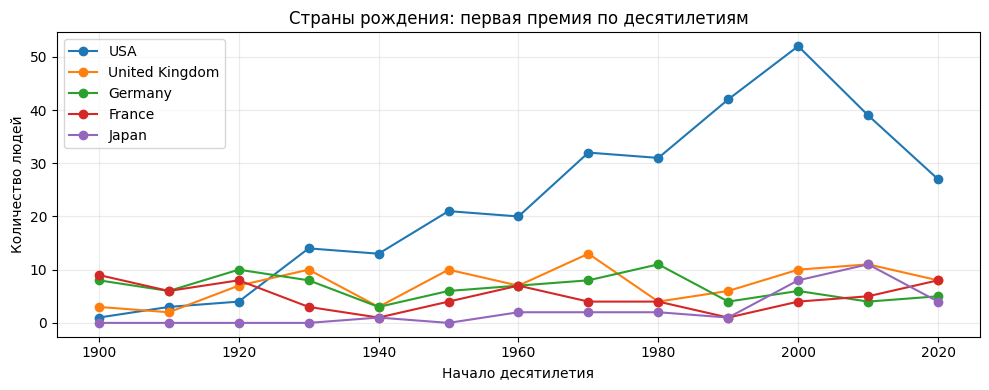

In [10]:
dated_persons = filter_data(
    persons, lambda row: row['first_decade'] is not None
)
first_decade_groups = group_by_attributes(dated_persons, ['first_decade'])
country_leaders = []
for (decade,), group in sorted(first_decade_groups.items()):
    leaders = country_top(group, 1)
    if leaders:
        country_leaders.append({'decade': decade, **leaders[0]})
show_table(country_leaders, [
    ('decade', 'Десятилетие'), ('country', 'Страна-лидер'),
    ('count', 'Лауреатов впервые'),
])

decades = [key[0] for key in sorted(first_decade_groups)]
fig, ax = plt.subplots(figsize=(10, 4))
for country in countries_total:
    counts = [
        sum(row['country_now'] == country['country']
            for row in first_decade_groups[(decade,)])
        for decade in decades
    ]
    ax.plot(decades, counts, marker='o', label=country['country'])
ax.set(title='Страны рождения: первая премия по десятилетиям',
       xlabel='Начало десятилетия', ylabel='Количество людей')
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


Больше всего лауреатов родились в **США (299)**!! Далее Великобритания (94), Германия (86), Франция (64) и Япония (31)., но по этим данным нельзя судить о миграции.

## 4. Возраст первой премии

вычитаю год рождения из года первой премии, возраст приблизительный и организации не учитываю.

In [11]:
age_persons = filter_data(persons, lambda row: row['age_first'] is not None)
assert all(row['age_first'] >= 0 for row in age_persons)
age_metrics = {
    'count': count_records,
    'mean': lambda rows: mean_value(rows, 'age_first'),
    'median': lambda rows: median_value(rows, 'age_first'),
    'minimum': lambda rows: min_value(rows, 'age_first'),
    'maximum': lambda rows: max_value(rows, 'age_first'),
}
age_columns = [
    ('count', 'Людей'), ('mean', 'Средний возраст'),
    ('median', 'Медиана'), ('minimum', 'Минимум'), ('maximum', 'Максимум'),
]
age_total = aggregate_data(age_persons, age_metrics)
print('Не хватает данных о возрасте:', len(persons) - len(age_persons))
show_table([age_total], age_columns)

age_by_category = [
    {'category': category, **aggregate_data(group, age_metrics)}
    for (category,), group in sorted(
        group_by_attributes(age_persons, ['first_category']).items()
    )
]
show_table(age_by_category, [('category', 'Первая категория')] + age_columns)

age_by_decade = [
    {'decade': decade, **aggregate_data(group, age_metrics)}
    for (decade,), group in sorted(
        group_by_attributes(age_persons, ['first_decade']).items()
    )
]
show_table(age_by_decade, [('decade', 'Десятилетие')] + age_columns)


Не хватает данных о возрасте: 0


| Людей | Средний возраст | Медиана | Минимум | Максимум |
| --- | --- | --- | --- | --- |
| 1000 | 60.61 | 61.0 | 17 | 97 |

| Первая категория | Людей | Средний возраст | Медиана | Минимум | Максимум |
| --- | --- | --- | --- | --- | --- |
| Chemistry | 199 | 59.43 | 58 | 35 | 97 |
| Economic Sciences | 101 | 67.21 | 67 | 47 | 90 |
| Literature | 123 | 65.04 | 67 | 42 | 88 |
| Peace | 112 | 60.97 | 62.0 | 17 | 87 |
| Physics | 230 | 57.79 | 56.0 | 25 | 96 |
| Physiology or Medicine | 235 | 59.02 | 58 | 32 | 87 |

| Десятилетие | Людей | Средний возраст | Медиана | Минимум | Максимум |
| --- | --- | --- | --- | --- | --- |
| 1900 | 56 | 57.84 | 58.0 | 35 | 85 |
| 1910 | 37 | 53.08 | 50 | 25 | 80 |
| 1920 | 54 | 54.98 | 56.0 | 32 | 86 |
| 1930 | 55 | 51.62 | 49 | 31 | 75 |
| 1940 | 40 | 58.02 | 56.0 | 39 | 81 |
| 1950 | 71 | 54.32 | 54 | 31 | 79 |
| 1960 | 74 | 56.45 | 57.0 | 32 | 87 |
| 1970 | 102 | 59.34 | 59.0 | 32 | 87 |
| 1980 | 93 | 60.54 | 60 | 37 | 83 |
| 1990 | 101 | 62.14 | 62 | 33 | 87 |
| 2000 | 119 | 65.87 | 64 | 40 | 90 |
| 2010 | 117 | 66.85 | 69 | 17 | 97 |
| 2020 | 81 | 69.38 | 69 | 39 | 96 |

проверяю крайние значения возраста и сравниваю среднее с медианой на графике

Пять самых молодых при первой премии:


| Имя | Год | Категория | Возраст |
| --- | --- | --- | --- |
| Malala Yousafzai | 2014 | Peace | 17 |
| Lawrence Bragg | 1915 | Physics | 25 |
| Nadia Murad | 2018 | Peace | 25 |
| Carl D. Anderson | 1936 | Physics | 31 |
| Paul A.M. Dirac | 1933 | Physics | 31 |

Пять самых старших при первой премии:


| Имя | Год | Категория | Возраст |
| --- | --- | --- | --- |
| John B. Goodenough | 2019 | Chemistry | 97 |
| Arthur Ashkin | 2018 | Physics | 96 |
| Henri B. Kagan | 2026 | Chemistry | 96 |
| John J. Hopfield | 2024 | Physics | 91 |
| Klaus Hasselmann | 2021 | Physics | 90 |

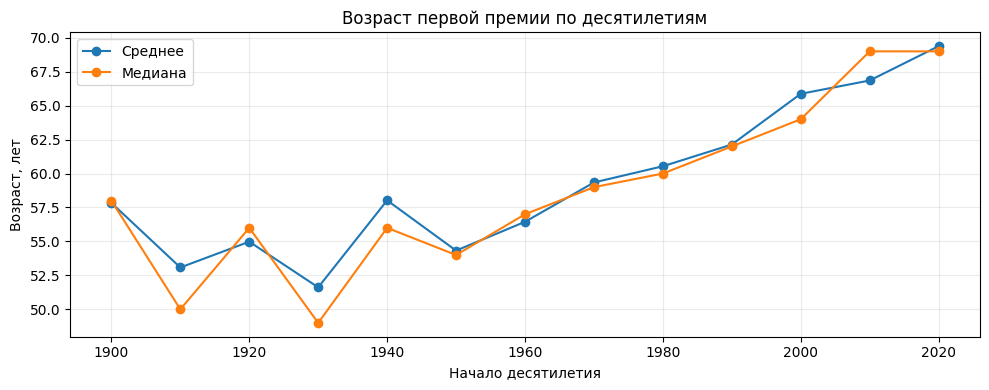

In [12]:
person_columns = [
    ('name', 'Имя'), ('first_year', 'Год'),
    ('first_category', 'Категория'), ('age_first', 'Возраст'),
]
print('Пять самых молодых при первой премии:')
show_table(top_n(age_persons, 'age_first', 5, reverse=False), person_columns)
print('Пять самых старших при первой премии:')
show_table(top_n(age_persons, 'age_first'), person_columns)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot([row['decade'] for row in age_by_decade],
        [row['mean'] for row in age_by_decade], marker='o', label='Среднее')
ax.plot([row['decade'] for row in age_by_decade],
        [row['median'] for row in age_by_decade], marker='o', label='Медиана')
ax.set(title='Возраст первой премии по десятилетиям',
       xlabel='Начало десятилетия', ylabel='Возраст, лет')
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


средний возраст **60,61 года**, медиана 61. Минимум 17, максимум 97 лет. В экономике средний возраст выше, чем в физике (67,21 и 57,79). С 1970-х он растет!!

## 5. Гендерное распределение

cчитаю людей, без повторов ID внутри группы. Учитываю и тех, кто отказался от премии

In [13]:
person_awards = []
for person in persons:
    for prize in person['prizes_relevant']:
        if prize['award_year'] is not None:
            person_awards.append({
                'id': person['id'],
                'gender': person['gender'],
                'category': prize['category_en'],
                'year': prize['award_year'],
                'decade': prize['award_year'] // 10 * 10,
            })


def gender_summary(records):
    # убираем повторы по id
    unique_persons = list({row['id']: row for row in records}.values())
    counts = Counter(row['gender'] for row in unique_persons)
    total = len(unique_persons)
    return {
        'people': total,
        'women': counts['female'],
        'men': counts['male'],
        'unknown': total - counts['female'] - counts['male'],
        'women_percent': 100 * counts['female'] / total if total else 0,
    }


gender_columns = [
    ('people', 'Всего людей'), ('women', 'Женщин'), ('men', 'Мужчин'),
    ('unknown', 'Пол не указан'), ('women_percent', 'Женщин, %'),
]
gender_total = gender_summary(persons)
show_table([gender_total], gender_columns)

gender_by_category = [
    {'category': category, **gender_summary(group)}
    for (category,), group in sorted(
        group_by_attributes(person_awards, ['category']).items()
    )
]
show_table(gender_by_category, [('category', 'Категория')] + gender_columns)


| Всего людей | Женщин | Мужчин | Пол не указан | Женщин, % |
| --- | --- | --- | --- | --- |
| 1000 | 69 | 931 | 0 | 6.9 |

| Категория | Всего людей | Женщин | Мужчин | Пол не указан | Женщин, % |
| --- | --- | --- | --- | --- | --- |
| Chemistry | 200 | 8 | 192 | 0 | 4.0 |
| Economic Sciences | 101 | 3 | 98 | 0 | 2.97 |
| Literature | 123 | 19 | 104 | 0 | 15.45 |
| Peace | 113 | 21 | 92 | 0 | 18.58 |
| Physics | 230 | 5 | 225 | 0 | 2.17 |
| Physiology or Medicine | 235 | 14 | 221 | 0 | 5.96 |

cчитаю долю и количество женщин по десятилетиям и категориям

In [14]:
gender_by_decade = [
    {'decade': decade, **gender_summary(group)}
    for (decade,), group in sorted(
        group_by_attributes(person_awards, ['decade']).items()
    )
]
show_table(gender_by_decade, [('decade', 'Десятилетие')] + gender_columns)

decade_category_groups = group_by_attributes(
    person_awards, ['decade', 'category']
)
women_by_decade_category = []
for decade in [row['decade'] for row in gender_by_decade]:
    counts = {'decade': decade}
    for category in categories:
        group = decade_category_groups.get((decade, category), [])
        counts[category] = gender_summary(group)['women']
    women_by_decade_category.append(counts)
print('Число женщин по категориям и десятилетиям:')
show_table(women_by_decade_category, [('decade', 'Десятилетие')] + [
    (category, category) for category in categories
])


| Десятилетие | Всего людей | Женщин | Мужчин | Пол не указан | Женщин, % |
| --- | --- | --- | --- | --- | --- |
| 1900 | 56 | 3 | 53 | 0 | 5.36 |
| 1910 | 38 | 1 | 37 | 0 | 2.63 |
| 1920 | 54 | 2 | 52 | 0 | 3.7 |
| 1930 | 55 | 3 | 52 | 0 | 5.45 |
| 1940 | 40 | 3 | 37 | 0 | 7.5 |
| 1950 | 71 | 0 | 71 | 0 | 0.0 |
| 1960 | 75 | 3 | 72 | 0 | 4.0 |
| 1970 | 103 | 4 | 99 | 0 | 3.88 |
| 1980 | 94 | 4 | 90 | 0 | 4.26 |
| 1990 | 101 | 7 | 94 | 0 | 6.93 |
| 2000 | 119 | 11 | 108 | 0 | 9.24 |
| 2010 | 117 | 13 | 104 | 0 | 11.11 |
| 2020 | 82 | 16 | 66 | 0 | 19.51 |

Число женщин по категориям и десятилетиям:


| Десятилетие | Chemistry | Economic Sciences | Literature | Peace | Physics | Physiology or Medicine |
| --- | --- | --- | --- | --- | --- | --- |
| 1900 | 0 | 0 | 1 | 1 | 1 | 0 |
| 1910 | 1 | 0 | 0 | 0 | 0 | 0 |
| 1920 | 0 | 0 | 2 | 0 | 0 | 0 |
| 1930 | 1 | 0 | 1 | 1 | 0 | 0 |
| 1940 | 0 | 0 | 1 | 1 | 0 | 1 |
| 1950 | 0 | 0 | 0 | 0 | 0 | 0 |
| 1960 | 1 | 0 | 1 | 0 | 1 | 0 |
| 1970 | 0 | 0 | 0 | 3 | 0 | 1 |
| 1980 | 0 | 0 | 0 | 1 | 0 | 3 |
| 1990 | 0 | 0 | 3 | 3 | 0 | 1 |
| 2000 | 1 | 1 | 3 | 2 | 0 | 4 |
| 2010 | 1 | 1 | 3 | 5 | 1 | 2 |
| 2020 | 3 | 1 | 4 | 4 | 2 | 2 |

cравниваю категории за разные периоды и строю график доли женщин

Все годы : Peace - 21
1901-1919 : Chemistry, Literature, Peace, Physics - 1
2010 и позже : Peace - 9


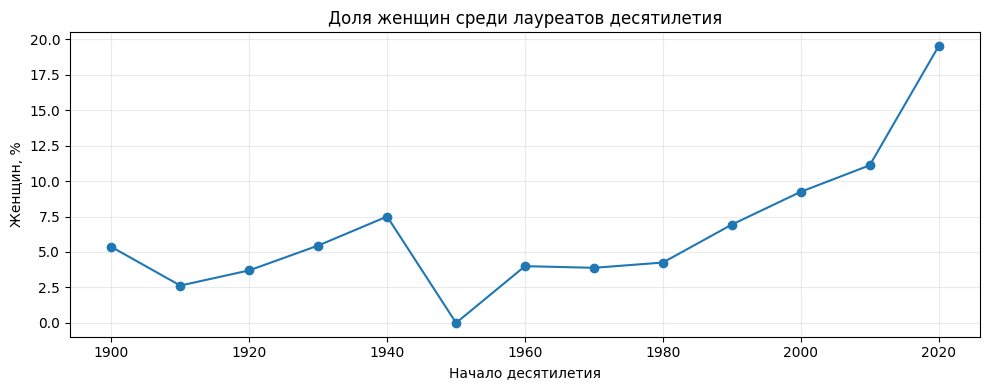

In [15]:
periods = [
    ('Все годы', person_awards),
    ('1901-1919', filter_data(person_awards, lambda row: row['year'] < 1920)),
    ('2010 и позже', filter_data(
        person_awards, lambda row: row['year'] >= 2010
    )),
]
for period, records in periods:
    groups = group_by_attributes(records, ['category'])
    counts = {category: gender_summary(group)['women']
              for (category,), group in groups.items()}
    maximum = max(counts.values())
    leaders = [category for category, count in counts.items()
               if count == maximum]
    print(period, ':', ', '.join(sorted(leaders)), '-', maximum)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot([row['decade'] for row in gender_by_decade],
        [row['women_percent'] for row in gender_by_decade], marker='o')
ax.set(title='Доля женщин среди лауреатов десятилетия',
       xlabel='Начало десятилетия', ylabel='Женщин, %')
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


из 1000 человек **69 женщин (6,9%)**! Больше всего в премии мира (21) и литературе (19). В 1901-1919 годах лидируют четыре категории, с 2010 года лидирует премия мира (9)

в 2010-х доля женщин 11,11%, в 2020-х пока 19,51%, а последнее десятилетие еще не закончилось.

## Итог

- больше всего лауреатов родились в США
- средний возраст первой премии около 61 года
- доля женщин выросла за последние десятилетия